In [ ]:
!pip -q install pyspark pyarrow requests


In [ ]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import requests, time, os
from concurrent.futures import ThreadPoolExecutor, as_completed

spark = (SparkSession.builder.appName("SolarPotentialIndia").master("local[*]")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())

In [ ]:
URL = "https://power.larc.nasa.gov/api/temporal/hourly/point"
test = requests.get(URL, params=dict(parameters="ALLSKY_SFC_SW_DWN,T2M", community="RE",
                    longitude=76.64, latitude=12.30, start="20230101", end="20230102", format="JSON"), timeout=120)
print("HTTP status:", test.status_code)
js = test.json()
print("Units:", {k: v.get("units") for k, v in js.get("parameters", {}).items()})
print("First keys:", list(js["properties"]["parameter"]["T2M"].items())[:3])

HTTP status: 200
Units: {'ALLSKY_SFC_SW_DWN': 'Wh/m^2', 'T2M': 'C'}
First keys: [('2023010100', 16.06), ('2023010101', 15.4), ('2023010102', 14.75)]


In [ ]:
CITIES = {
 "Mysuru":(12.30,76.64),"Bengaluru":(12.97,77.59),"Chennai":(13.08,80.27),"Hyderabad":(17.39,78.49),
 "Mumbai":(19.08,72.88),"Pune":(18.52,73.86),"Ahmedabad":(23.02,72.57),"Jaipur":(26.91,75.79),
 "Jodhpur":(26.24,73.02),"Delhi":(28.61,77.21),"Lucknow":(26.85,80.95),"Kanpur":(26.45,80.35),
 "Bhopal":(23.26,77.41),"Indore":(22.72,75.86),"Nagpur":(21.15,79.09),"Raipur":(21.25,81.63),
 "Kolkata":(22.57,88.36),"Bhubaneswar":(20.30,85.82),"Patna":(25.59,85.14),"Guwahati":(26.14,91.74),
 "Chandigarh":(30.73,76.78),"Amritsar":(31.63,74.87),"Srinagar":(34.08,74.80),"Leh":(34.15,77.58),
 "Shimla":(31.10,77.17),"Dehradun":(30.32,78.03),"Ranchi":(23.34,85.31),"Visakhapatnam":(17.69,83.22),
 "Vijayawada":(16.51,80.65),"Kochi":(9.93,76.27),"Thiruvananthapuram":(8.52,76.94),"Coimbatore":(11.02,76.96),
 "Madurai":(9.92,78.12),"Mangaluru":(12.91,74.86),"Panaji":(15.50,73.83),"Surat":(21.17,72.83),
 "Rajkot":(22.30,70.80),"Bhuj":(23.25,69.67),"Udaipur":(24.59,73.71),"Bikaner":(28.02,73.31),
 "Jaisalmer":(26.92,70.90),"Agra":(27.18,78.02),"Varanasi":(25.32,83.00),"Gwalior":(26.22,78.18),
 "Jabalpur":(23.18,79.99),"Aurangabad":(19.88,75.34),"Kolhapur":(16.70,74.24),"Hubballi":(15.36,75.12),
 "Ballari":(15.14,76.92),"Tirupati":(13.63,79.42),"Port Blair":(11.62,92.73),"Imphal":(24.82,93.94),
 "Agartala":(23.83,91.28),"Gangtok":(27.34,88.61),"Jammu":(32.73,74.86),"Puducherry":(11.93,79.83),
 "Warangal":(17.97,79.60),
}
YEARS = range(2018, 2024)
OUT = "/content/nasa_power"
os.makedirs(OUT, exist_ok=True)
print(len(CITIES), "cities x", len(YEARS), "years =", len(CITIES) * len(YEARS), "downloads")

57 cities x 6 years = 342 downloads


In [ ]:
def fetch(city, lat, lon, year):
    fn = f"{OUT}/{city}_{year}.parquet"
    if os.path.exists(fn):
        return fn
    params = dict(parameters="ALLSKY_SFC_SW_DWN,T2M", community="RE", longitude=lon, latitude=lat,
                  start=f"{year}0101", end=f"{year}1231", format="JSON")
    r = None
    for attempt in range(5):
        try:
            r = requests.get(URL, params=params, timeout=180)
            if r.status_code == 200:
                break
        except requests.RequestException:
            pass
        r = None
        time.sleep(5 * (attempt + 1))
    if r is None:
        return None
    p = r.json()["properties"]["parameter"]
    df = pd.DataFrame({"ghi": p["ALLSKY_SFC_SW_DWN"], "t2m": p["T2M"]})
    df.index.name = "stamp"
    df = df.reset_index()
    df = df[(df["ghi"] > -900) & (df["t2m"] > -900)]       # -999 means missing
    s = df["stamp"].astype(str)
    df["year"] = s.str[0:4].astype(int); df["month"] = s.str[4:6].astype(int)
    df["day"] = s.str[6:8].astype(int);  df["hour"] = s.str[8:10].astype(int)
    df["city"] = city; df["lat"] = lat; df["lon"] = lon
    df.drop(columns="stamp").to_parquet(fn, index=False)
    return fn

jobs = [(c, la, lo, y) for c, (la, lo) in CITIES.items() for y in YEARS]
done, failed = 0, []
with ThreadPoolExecutor(max_workers=4) as ex:
    futs = {ex.submit(fetch, *j): j for j in jobs}
    for f in as_completed(futs):
        if f.result() is None:
            failed.append(futs[f])
        done += 1
        if done % 20 == 0:
            print(f"{done}/{len(jobs)} finished")
print("Failed downloads:", len(failed), "(run this cell again to retry them)")

20/342 finished
40/342 finished
60/342 finished
80/342 finished
100/342 finished
120/342 finished
140/342 finished
160/342 finished
180/342 finished
200/342 finished
220/342 finished
240/342 finished
260/342 finished
280/342 finished
300/342 finished
320/342 finished
340/342 finished
Failed downloads: 0 (run this cell again to retry them)


In [ ]:
df = spark.read.parquet(OUT)
t0 = time.time()
n = df.count()
print(f"Rows loaded: {n:,}   Cities: {df.select('city').distinct().count()}   "
      f"Years: {df.select('year').distinct().count()}   ({time.time()-t0:.1f} s)")
size_mb = sum(os.path.getsize(f"{OUT}/{f}") for f in os.listdir(OUT)) / 1e6
print(f"Size on disk: {size_mb:.0f} MB (compressed Parquet)")
df.show(50)
df.cache()

Rows loaded: 2,997,288   Cities: 57   Years: 6   (13.1 s)
Size on disk: 20 MB (compressed Parquet)
+------+------+----+-----+---+----+----+-----+-----+
|   ghi|   t2m|year|month|day|hour|city|  lat|  lon|
+------+------+----+-----+---+----+----+-----+-----+
|   0.0|-25.84|2020|    1|  1|   0| Leh|34.15|77.58|
|   0.0| -26.8|2020|    1|  1|   1| Leh|34.15|77.58|
|   0.0|-27.84|2020|    1|  1|   2| Leh|34.15|77.58|
|   0.0|-29.12|2020|    1|  1|   3| Leh|34.15|77.58|
|   0.0|-30.25|2020|    1|  1|   4| Leh|34.15|77.58|
|   0.0|-31.22|2020|    1|  1|   5| Leh|34.15|77.58|
|   0.0|-31.98|2020|    1|  1|   6| Leh|34.15|77.58|
|  35.0|-32.36|2020|    1|  1|   7| Leh|34.15|77.58|
| 131.4|-30.64|2020|    1|  1|   8| Leh|34.15|77.58|
|219.38|-26.74|2020|    1|  1|   9| Leh|34.15|77.58|
|236.88|-22.77|2020|    1|  1|  10| Leh|34.15|77.58|
|244.55|-18.05|2020|    1|  1|  11| Leh|34.15|77.58|
| 201.7|-16.26|2020|    1|  1|  12| Leh|34.15|77.58|
|207.43|-15.82|2020|    1|  1|  13| Leh|34.15|77.58|


DataFrame[ghi: double, t2m: double, year: bigint, month: bigint, day: bigint, hour: bigint, city: string, lat: double, lon: double]

Spark aggregation over 2,997,288 rows took 14.8 s


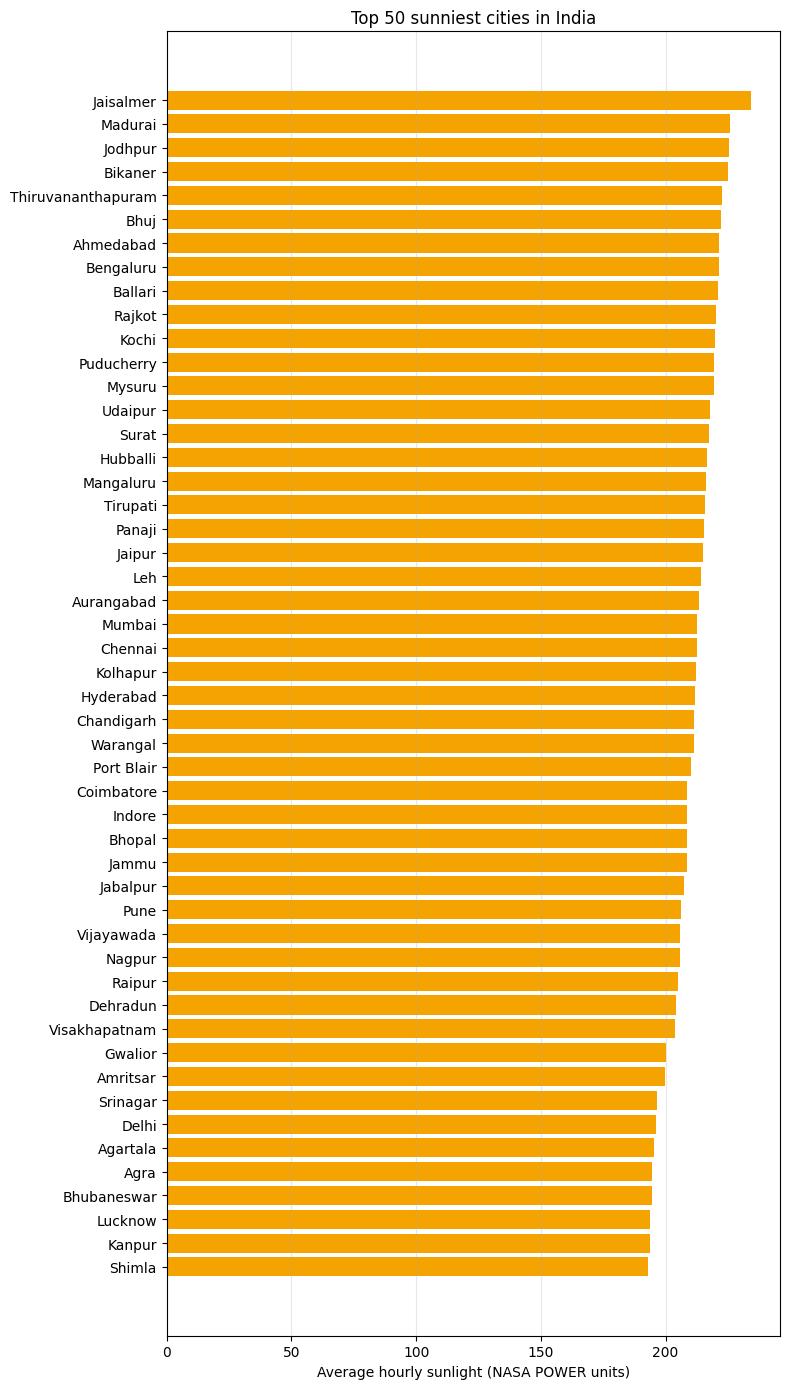

In [ ]:
t0 = time.time()
city_stats = (df.groupBy("city", "lat", "lon")
              .agg(F.avg("ghi").alias("avg_ghi"), F.avg("t2m").alias("avg_temp"))
              .orderBy(F.desc("avg_ghi")).toPandas())
print(f"Spark aggregation over {n:,} rows took {time.time()-t0:.1f} s")

top50 = city_stats.head(50).iloc[::-1]          # reversed so the sunniest city sits at the top
plt.figure(figsize=(8, 14))
plt.barh(top50["city"], top50["avg_ghi"], color="#f4a300")
plt.title("Top 50 sunniest cities in India")
plt.xlabel("Average hourly sunlight (NASA POWER units)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("B1_city_ranking_top50.png", dpi=200); plt.show()

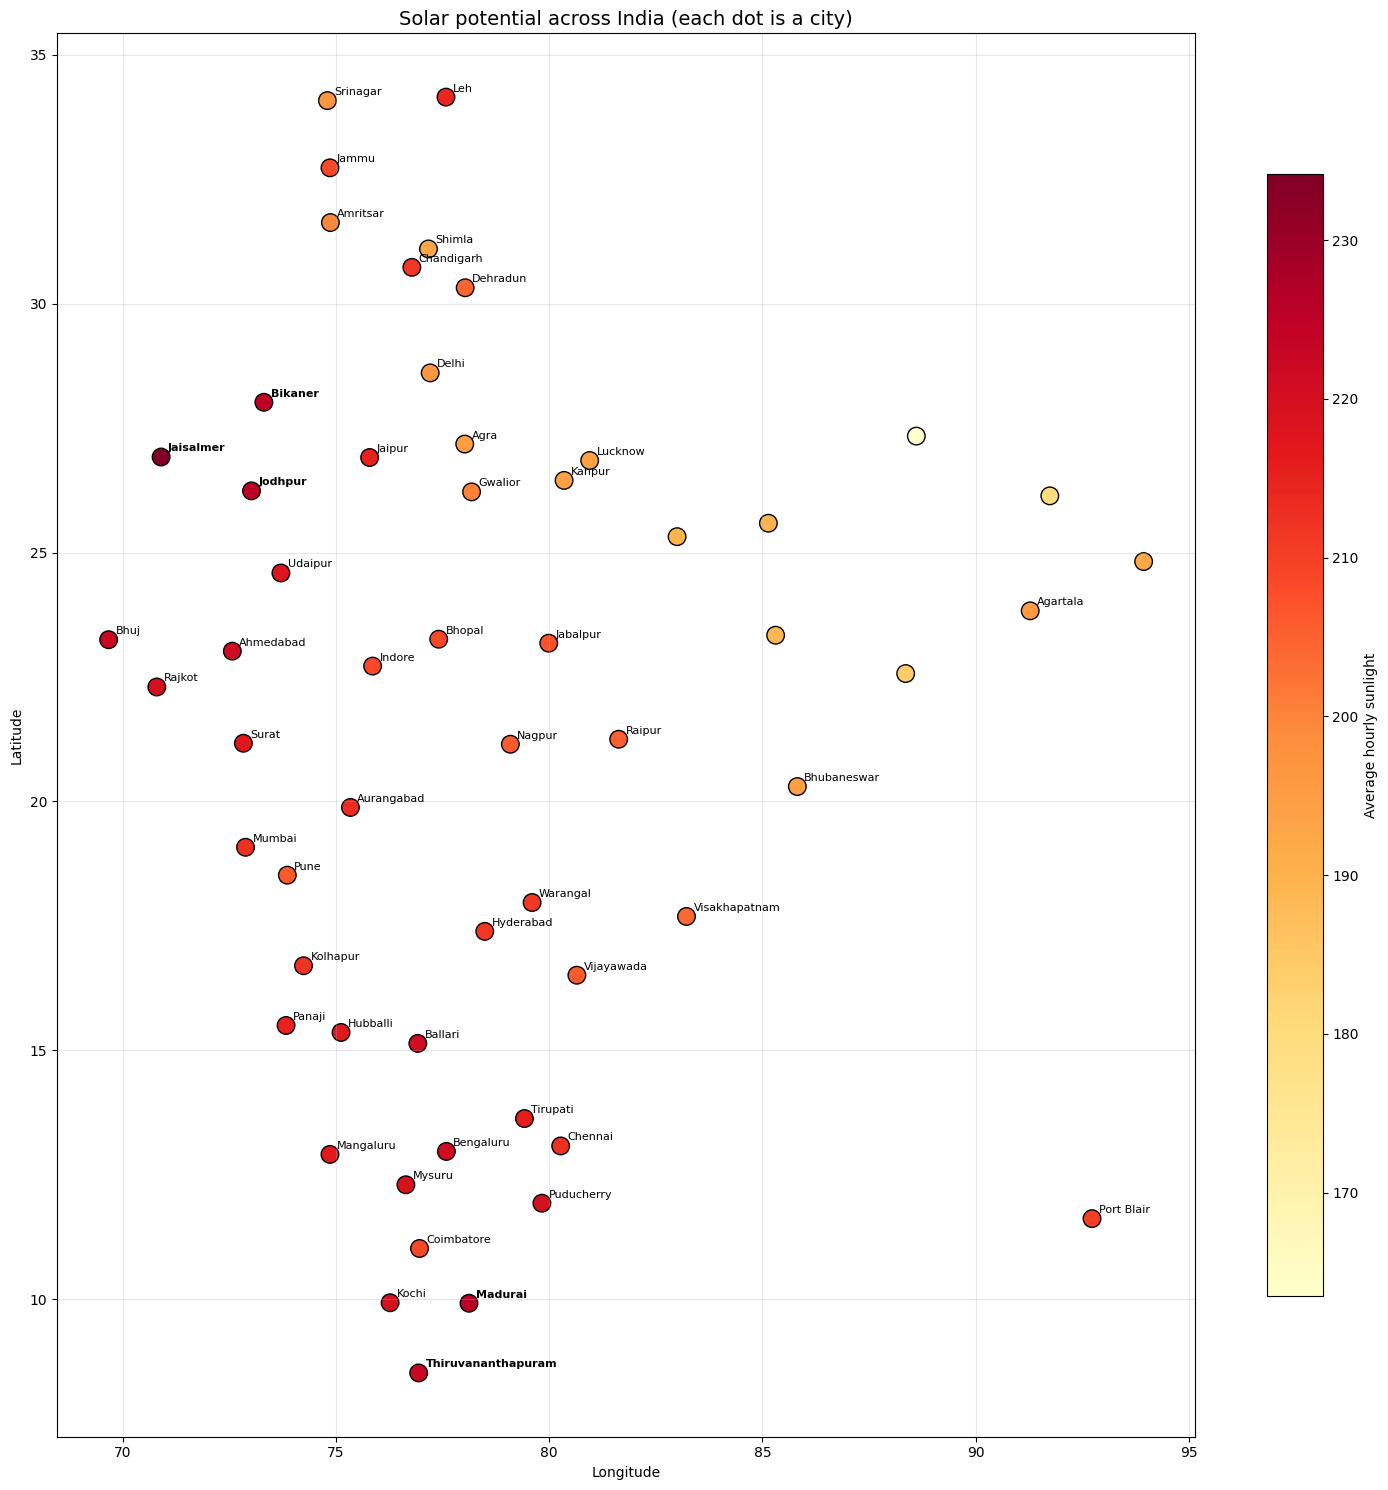

In [ ]:
plt.figure(figsize=(15, 15))
sc = plt.scatter(city_stats["lon"], city_stats["lat"], c=city_stats["avg_ghi"],
                 cmap="YlOrRd", s=160, edgecolor="k")
plt.colorbar(sc, label="Average hourly sunlight", shrink=0.8)

# Label the top 50 cities, with the sunniest 5 in bold
for i, (_, r) in enumerate(city_stats.head(50).iterrows()):
    plt.annotate(r["city"], (r["lon"], r["lat"]), fontsize=8,
                 fontweight="bold" if i < 5 else "normal",
                 xytext=(5, 4), textcoords="offset points")

plt.title("Solar potential across India (each dot is a city)", fontsize=14)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("B2_potential_map.png", dpi=250); plt.show()

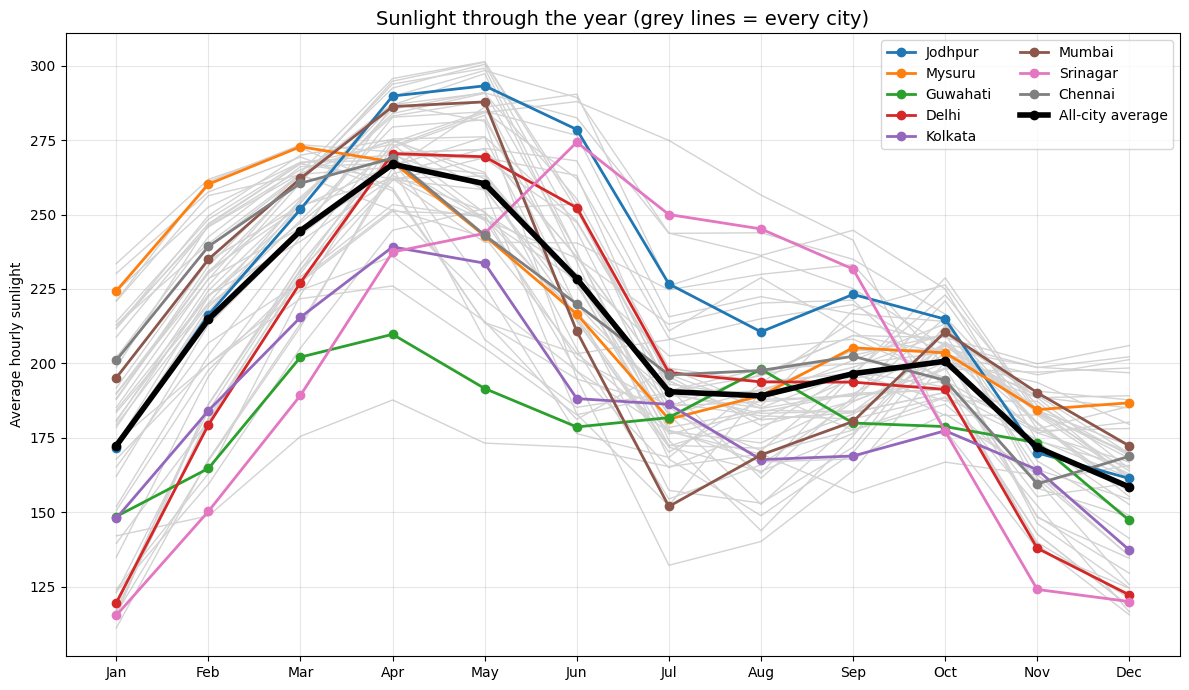

In [ ]:
monthly = df.groupBy("month").agg(F.avg("ghi").alias("avg_ghi")).orderBy("month").toPandas()
all_cm = (df.groupBy("city", "month").agg(F.avg("ghi").alias("avg_ghi"))
            .orderBy("month").toPandas())
highlight = [c for c in ["Jodhpur", "Mysuru", "Guwahati", "Delhi", "Kolkata", "Mumbai", "Srinagar", "Chennai"]
             if c in CITIES]

plt.figure(figsize=(12, 7))
for c, d in all_cm.groupby("city"):                       # every city as a faint grey line
    plt.plot(d["month"], d["avg_ghi"], color="lightgrey", linewidth=1, zorder=1)
for c in highlight:                                       # chosen cities in colour
    d = all_cm[all_cm["city"] == c]
    plt.plot(d["month"], d["avg_ghi"], marker="o", linewidth=2, label=c, zorder=2)
plt.plot(monthly["month"], monthly["avg_ghi"], "k-o", linewidth=4, label="All-city average", zorder=3)

plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Sunlight through the year (grey lines = every city)", fontsize=14)
plt.ylabel("Average hourly sunlight"); plt.legend(ncol=2); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("B3_monthly_pattern.png", dpi=250); plt.show()

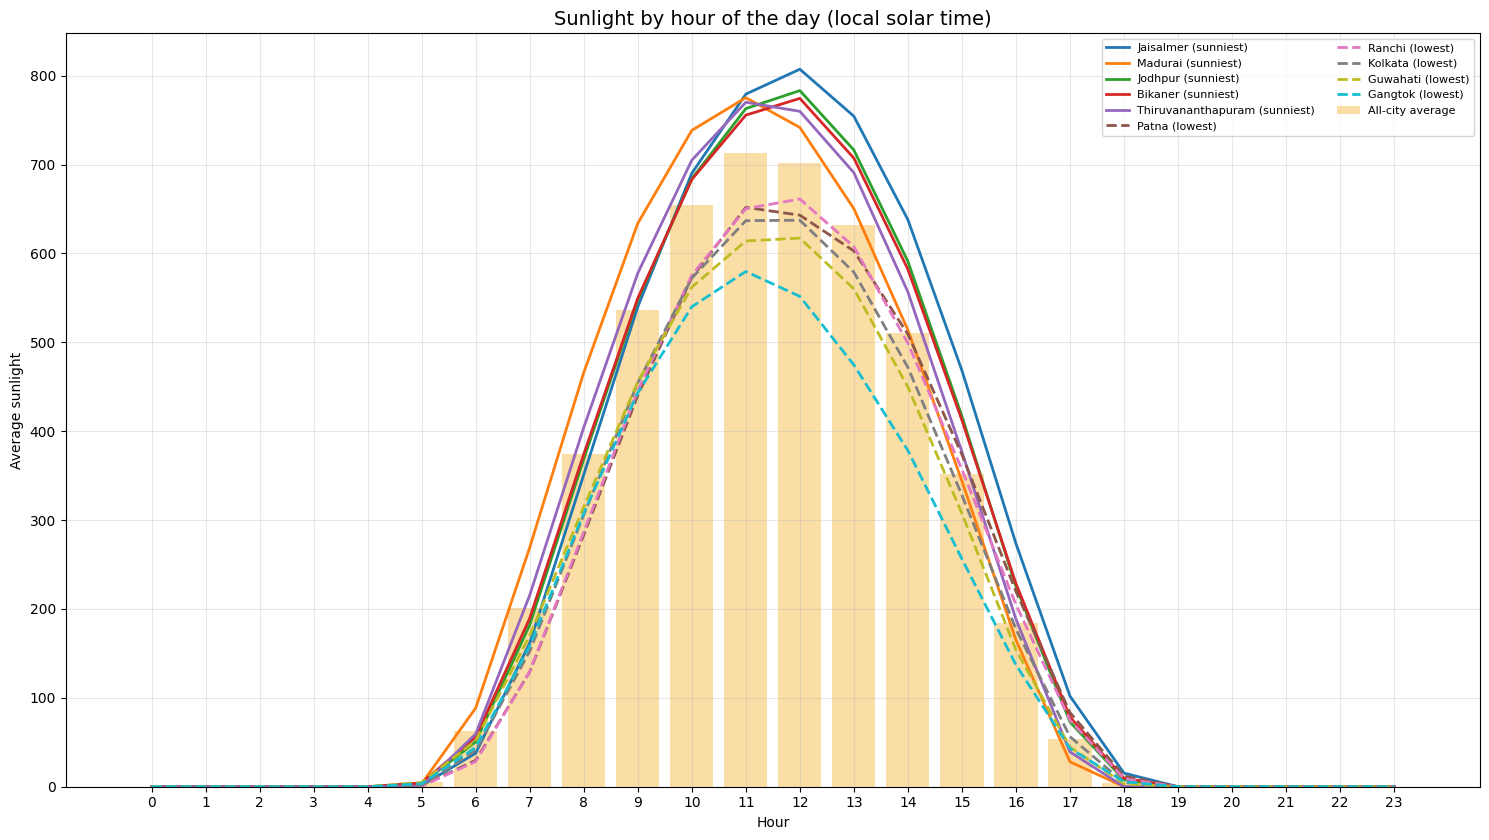

In [ ]:
hourly = df.groupBy("hour").agg(F.avg("ghi").alias("avg_ghi")).orderBy("hour").toPandas()
hc = (df.groupBy("city", "hour").agg(F.avg("ghi").alias("avg_ghi"))
        .orderBy("hour").toPandas())
top5 = list(city_stats.head(5)["city"])
bottom5 = list(city_stats.tail(5)["city"])

plt.figure(figsize=(15, 8.5))
plt.bar(hourly["hour"], hourly["avg_ghi"], color="#f4a300", alpha=0.35, label="All-city average")
for c in top5:
    d = hc[hc["city"] == c]
    plt.plot(d["hour"], d["avg_ghi"], linewidth=2, label=f"{c} (sunniest)")
for c in bottom5:
    d = hc[hc["city"] == c]
    plt.plot(d["hour"], d["avg_ghi"], linewidth=2, linestyle="--", label=f"{c} (lowest)")

plt.xticks(range(0, 24))
plt.title("Sunlight by hour of the day (local solar time)", fontsize=14)
plt.xlabel("Hour"); plt.ylabel("Average sunlight")
plt.legend(ncol=2, fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("B4_hourly_pattern.png", dpi=250); plt.show()

Biggest seasonal swing (need most storage/backup):
      city  best_month  worst_month  best_to_worst
     Jammu       290.4        116.1            2.5
  Amritsar       272.2        111.1            2.4
  Srinagar       274.3        115.4            2.4
Chandigarh       284.7        122.9            2.3
       Leh       287.9        124.1            2.3
   Lucknow       271.9        118.4            2.3
    Kanpur       271.9        118.4            2.3
      Agra       270.0        117.3            2.3
  Varanasi       261.7        115.4            2.3
     Delhi       270.5        119.6            2.3

Steadiest sunlight through the year:
              city  best_month  worst_month  best_to_worst
           Ballari       275.3        182.7            1.5
            Mysuru       272.8        181.3            1.5
           Madurai       267.0        177.4            1.5
             Kochi       272.5        185.6            1.5
          Agartala       235.9        160.8            

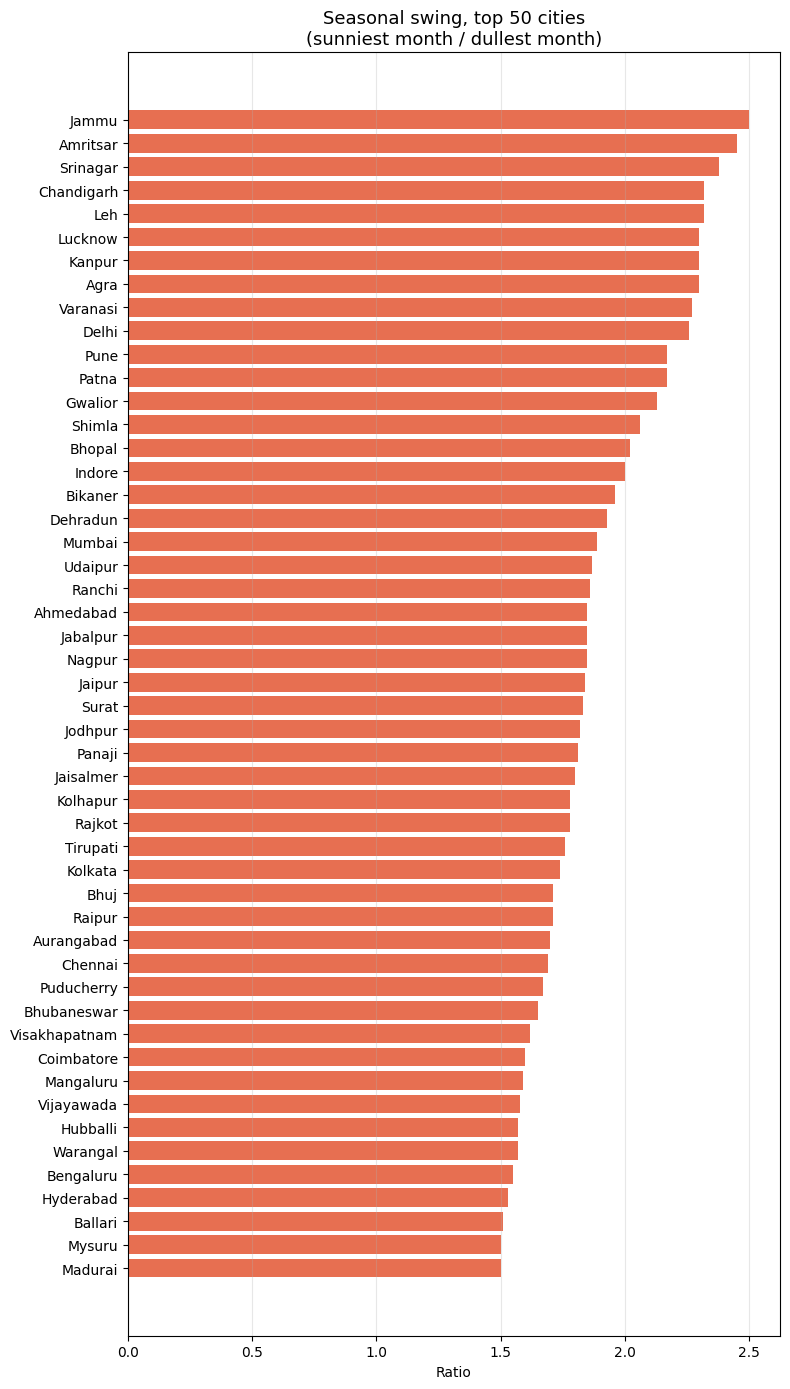

In [ ]:
cm = df.groupBy("city", "month").agg(F.avg("ghi").alias("m_ghi"))
season = (cm.groupBy("city").agg(F.max("m_ghi").alias("best_month"), F.min("m_ghi").alias("worst_month"))
            .withColumn("best_to_worst", F.round(F.col("best_month") / F.col("worst_month"), 2))
            .orderBy(F.desc("best_to_worst")).toPandas())

print("Biggest seasonal swing (need most storage/backup):")
print(season.head(10).round(1).to_string(index=False))
print("\nSteadiest sunlight through the year:")
print(season.tail(10).round(1).to_string(index=False))

s50 = season.head(50).iloc[::-1]                          # biggest swing at the top
plt.figure(figsize=(8, 14))
plt.barh(s50["city"], s50["best_to_worst"], color="#e76f51")
plt.title("Seasonal swing, top 50 cities\n(sunniest month / dullest month)", fontsize=13)
plt.xlabel("Ratio"); plt.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("B5_seasonal_swing_top50.png", dpi=250); plt.show()

In [ ]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import textwrap, glob

def make_pdf(filename, title, summary_lines, tables, image_files):
    with PdfPages(filename) as pdf:
        # Page 1: title and key numbers
        fig = plt.figure(figsize=(11.69, 8.27))
        fig.text(0.05, 0.92, title, fontsize=20, fontweight="bold")
        y = 0.84
        for line in summary_lines:
            for part in textwrap.wrap(line, 110):
                fig.text(0.05, y, part, fontsize=12); y -= 0.04
            y -= 0.01
        pdf.savefig(fig); plt.close(fig)
        # Table pages
        for ttl, tdf in tables:
            fig, ax = plt.subplots(figsize=(11.69, 8.27)); ax.axis("off")
            ax.set_title(ttl, fontsize=16, fontweight="bold")
            tbl = ax.table(cellText=tdf.round(2).values, colLabels=list(tdf.columns),
                           loc="upper center", cellLoc="center")
            tbl.auto_set_font_size(False)
            tbl.set_fontsize(7 if len(tdf) > 25 else 10)
            pdf.savefig(fig); plt.close(fig)
        # One chart per page
        for f in image_files:
            fig, ax = plt.subplots(figsize=(11.69, 8.27))
            ax.imshow(mpimg.imread(f)); ax.axis("off")
            ax.set_title(f, fontsize=9)
            pdf.savefig(fig, dpi=200); plt.close(fig)
    print("Saved", filename)

In [ ]:
from google.colab import files

t0 = time.time(); df.groupBy("city").count().collect(); spark_secs = time.time() - t0
units = {k: v.get("units") for k, v in js.get("parameters", {}).items()}
size_mb = sum(os.path.getsize(f"{OUT}/{f}") for f in os.listdir(OUT)) / 1e6

summary_B = [
    "Dataset: NASA POWER hourly sunlight (ALLSKY_SFC_SW_DWN) and air temperature (T2M) for Indian cities",
    f"Rows processed in PySpark: {n:,}",
    f"Cities: {df.select('city').distinct().count()} | Years: {df.select('year').distinct().count()} | Size on disk: {size_mb:.0f} MB",
    f"Spark full-dataset query time: {spark_secs:.1f} seconds",
    f"Units reported by NASA: {units}",
    "Top 5 sunniest cities: " + ", ".join(city_stats.head(5)["city"]),
    "Biggest seasonal swing (need most storage/backup): " + ", ".join(season.head(5)["city"]),
]
make_pdf("PartB_results.pdf", "Part B: India-wide solar potential with PySpark",
         summary_B,
         [("Top 50 cities by sunlight", city_stats.head(50)[["city", "avg_ghi", "avg_temp"]]),
          ("Seasonal swing by city", season.head(50)[["city", "best_month", "worst_month", "best_to_worst"]])],
         sorted(glob.glob("B*.png")))
files.download("PartB_results.pdf")

Saved PartB_results.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
LOAD_W = 50
BATTERY_WH = 1200
PR = 0.75
TARGET = 0.99
DESIGN_W = 300
PANEL_SIZES = [100, 150, 200, 300, 400, 600, 800, 1200]

In [ ]:
print("PANEL_SIZES:", PANEL_SIZES)
print("DESIGN_W:", DESIGN_W)
print("BATTERY_WH:", BATTERY_WH)
print("PR:", PR)
print("LOAD_W:", LOAD_W)
print("TARGET:", TARGET)
print("DataFrame rows:", df.count())

PANEL_SIZES: [100, 150, 200, 300, 400, 600, 800, 1200]
DESIGN_W: 300
BATTERY_WH: 1200
PR: 0.75
LOAD_W: 50
TARGET: 0.99
DataFrame rows: 2997288


In [ ]:
import time
import pandas as pd

from pyspark.sql.types import (
    StructType,
    StructField,
    StringType,
    DoubleType,
    LongType
)

# Count hourly records before simulation
n_B = df.count()

# Simulation function
def simulate(pdf):

    pdf = pdf.sort_values(
        ["year", "month", "day", "hour"]
    )

    g = pdf["ghi"].astype(float).tolist()
    months = pdf["month"].astype(int).tolist()

    city = pdf["city"].iloc[0]
    n = len(g)

    out = []

    for P in PANEL_SIZES:

        k = P * PR / 1000.0

        soc = float(BATTERY_WH)

        ok = 0

        okm = [0] * 13
        nm = [0] * 13

        for x, mo in zip(g, months):

            soc += x * k - LOAD_W

            if soc > BATTERY_WH:
                soc = BATTERY_WH

            nm[mo] += 1

            if soc >= 0:
                ok += 1
                okm[mo] += 1

            else:
                soc = 0.0

        # Whole-year uptime (month = 0)
        out.append(
            (city, float(P), 0, ok / n)
        )

        # Monthly uptime for design panel
        if P == DESIGN_W:

            for mo in range(1, 13):

                uptime = (
                    okm[mo] / nm[mo]
                    if nm[mo] else float("nan")
                )

                out.append(
                    (city, float(P), mo, uptime)
                )

    return pd.DataFrame(
        out,
        columns=["city", "panel_w", "month", "uptime"]
    )


# Output schema
schema = StructType([
    StructField("city", StringType()),
    StructField("panel_w", DoubleType()),
    StructField("month", LongType()),
    StructField("uptime", DoubleType())
])


# Run simulation
t0 = time.time()

sim = (
    df.select(
        "city",
        "year",
        "month",
        "day",
        "hour",
        "ghi"
    )
    .groupBy("city")
    .applyInPandas(simulate, schema=schema)
    .toPandas()
)

elapsed = time.time() - t0

print("=" * 60)
print("SOLAR BATTERY SIMULATION COMPLETED")
print("=" * 60)

print(f"Cities simulated       : {sim['city'].nunique()}")
print(f"Hourly records         : {n_B:,}")
print(f"Simulation time        : {elapsed:.2f} seconds")


# Whole-year uptime table
year_up = sim[
    sim["month"] == 0
].pivot(
    index="city",
    columns="panel_w",
    values="uptime"
)

year_up.columns = [
    int(c) for c in year_up.columns
]


# Find minimum panel size meeting target uptime
def first_ok(row):

    ok = [
        p for p in PANEL_SIZES
        if p in row.index
        and pd.notna(row[p])
        and row[p] >= TARGET
    ]

    return float(ok[0]) if ok else float("nan")


# Create station sizing results
sizing = pd.DataFrame({

    "city": year_up.index,

    "min_panel_w": year_up.apply(
        first_ok,
        axis=1
    ).values,

    "avail_design": year_up[DESIGN_W].values

})


# Merge city statistics
sizing = sizing.merge(
    city_stats[
        ["city", "lat", "lon", "avg_ghi"]
    ],
    on="city",
    how="left"
)


# Sort and round results
sizing = sizing.sort_values(
    "min_panel_w"
).round(3)


# Export CSV
sizing.to_csv(
    "C_station_sizing.csv",
    index=False
)


# Display results
print("\n" + "=" * 75)
print("INDIA-WIDE SOLAR STATION SIZING RESULTS")
print("=" * 75)

print(
    sizing[
        [
            "city",
            "min_panel_w",
            "avail_design",
            "avg_ghi"
        ]
    ].to_string(index=False)
)

print("\nSaved successfully: C_station_sizing.csv")

SOLAR BATTERY SIMULATION COMPLETED
Cities simulated       : 57
Hourly records         : 2,997,288
Simulation time        : 14.23 seconds

INDIA-WIDE SOLAR STATION SIZING RESULTS
              city  min_panel_w  avail_design  avg_ghi
          Agartala        600.0         0.827  195.571
         Ahmedabad        600.0         0.874  221.518
           Ballari        600.0         0.898  220.925
        Aurangabad        600.0         0.859  213.446
         Bengaluru        600.0         0.900  221.304
        Coimbatore        600.0         0.861  208.556
           Bikaner        600.0         0.886  225.242
              Bhuj        600.0         0.893  222.387
           Chennai        600.0         0.872  212.420
         Jaisalmer        600.0         0.915  234.188
          Jabalpur        600.0         0.834  207.325
            Indore        600.0         0.825  208.540
         Hyderabad        600.0         0.867  211.636
            Imphal        600.0         0.811  192.1

57 of 57 cities reach 99% uptime with a panel of up to 1200 W


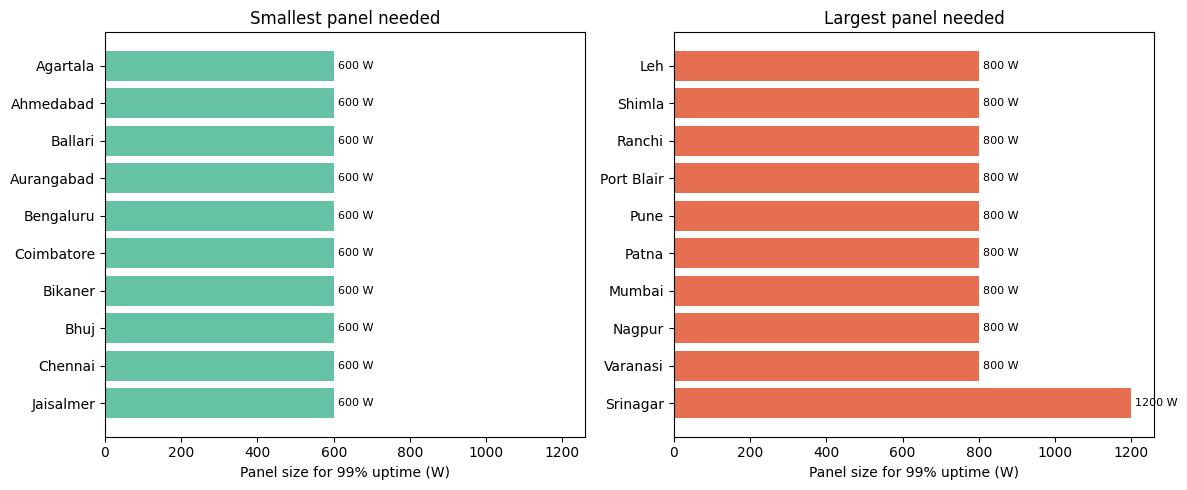

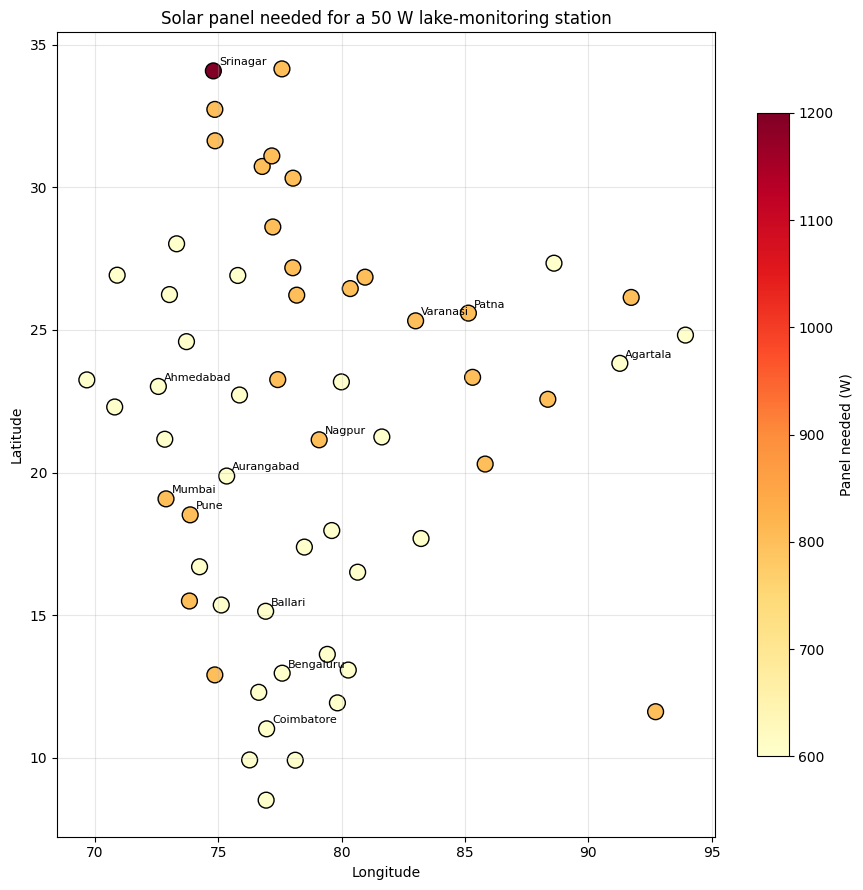

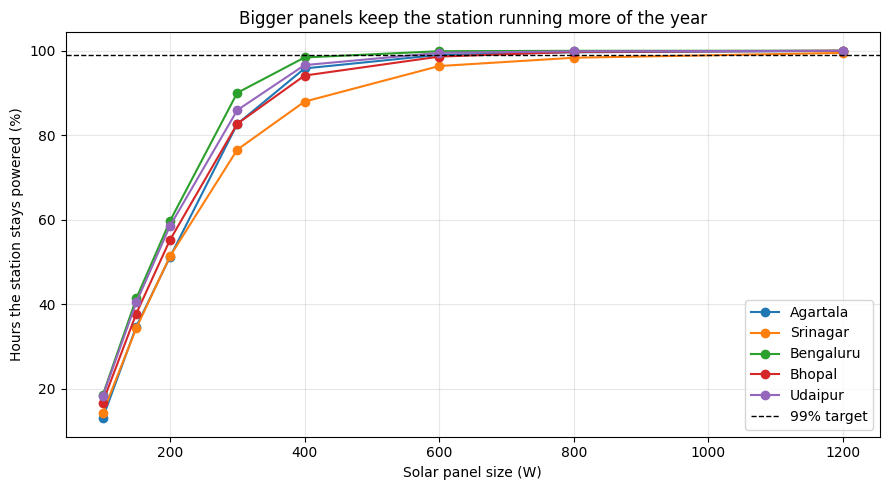

Smallest panel: Agartala (600 W). Largest: Srinagar (1200 W).
Largest need is about 2.0x the smallest (say 'at least' if a city never reached the target).


In [ ]:
import matplotlib.pyplot as plt

s = sizing.copy()
cap_val = max(PANEL_SIZES) * 1.25
s["plot_w"] = s["min_panel_w"].fillna(cap_val); s = s.sort_values("plot_w")
n_ok = int(s["min_panel_w"].notna().sum())
def label(v): return f">{max(PANEL_SIZES)} W" if v >= cap_val else f"{v:.0f} W"
print(f"{n_ok} of {len(s)} cities reach {TARGET:.0%} uptime with a panel of up to {max(PANEL_SIZES)} W")

low, high = s.head(10).iloc[::-1], s.tail(10)
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, d, ttl, col in [(axs[0], low, "Smallest panel needed", "#66c2a5"),
                        (axs[1], high.iloc[::-1], "Largest panel needed", "#e76f51")]:
    ax.barh(d["city"], d["plot_w"], color=col)
    for y, (_, r) in enumerate(d.iterrows()):
        ax.text(r["plot_w"] + 10, y, label(r["plot_w"]), va="center", fontsize=8)
    ax.set_title(ttl); ax.set_xlabel("Panel size for 99% uptime (W)")
plt.tight_layout(); plt.savefig("C1_panel_needed.png", dpi=200); plt.show()

plt.figure(figsize=(9, 9))
sc = plt.scatter(s["lon"], s["lat"], c=s["plot_w"], cmap="YlOrRd", s=130, edgecolor="k")
plt.colorbar(sc, label="Panel needed (W)", shrink=0.8)
for _, r in pd.concat([s.head(6), s.tail(6)]).drop_duplicates("city").iterrows():
    plt.annotate(r["city"], (r["lon"], r["lat"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.title("Solar panel needed for a 50 W lake-monitoring station")
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("C2_panel_map.png", dpi=200); plt.show()

pick = list(dict.fromkeys([s.iloc[0]["city"], s.iloc[-1]["city"]] +
                          [c for c in ["Bengaluru", "Bhopal", "Udaipur"] if c in CITIES]))
plt.figure(figsize=(9, 5))
for c in pick:
    plt.plot(PANEL_SIZES, year_up.loc[c, PANEL_SIZES].values * 100, marker="o", label=c)
plt.axhline(TARGET * 100, color="k", linestyle="--", linewidth=1, label=f"{TARGET:.0%} target")
plt.xlabel("Solar panel size (W)"); plt.ylabel("Hours the station stays powered (%)")
plt.title("Bigger panels keep the station running more of the year")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("C3_uptime_vs_panel.png", dpi=200); plt.show()

small, big = s.iloc[0], s.iloc[-1]
print(f"Smallest panel: {small['city']} ({label(small['plot_w'])}). Largest: {big['city']} ({label(big['plot_w'])}).")
print(f"Largest need is about {big['plot_w']/small['plot_w']:.1f}x the smallest (say 'at least' if a city never reached the target).")

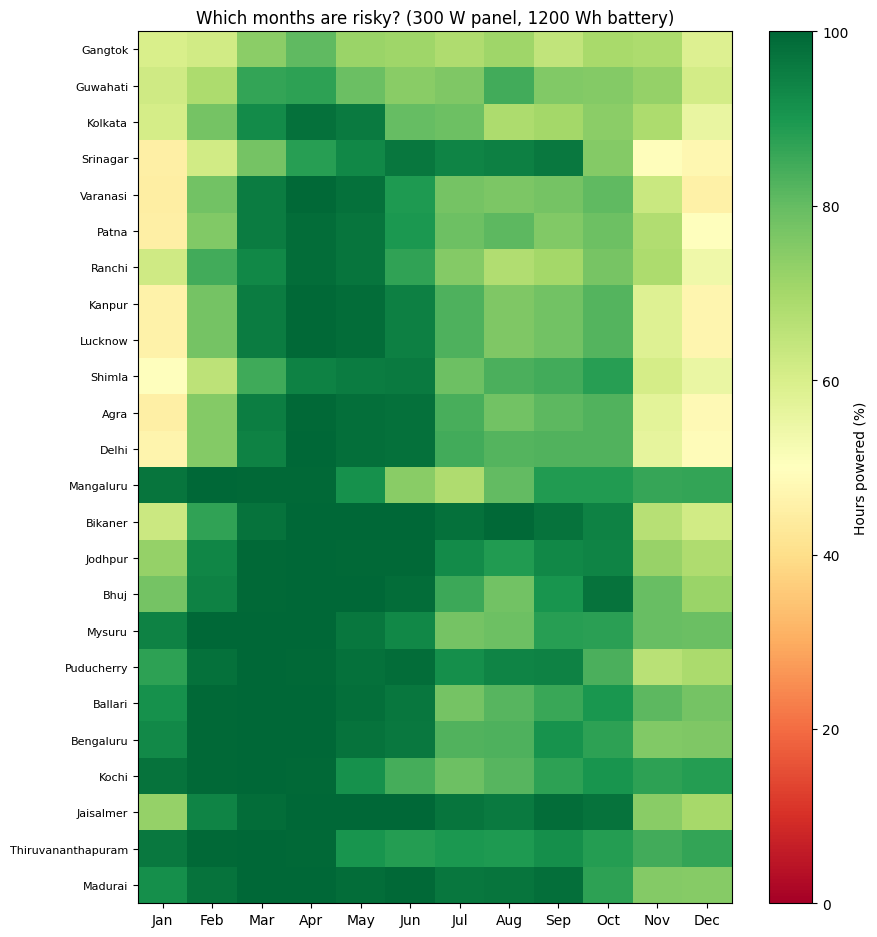

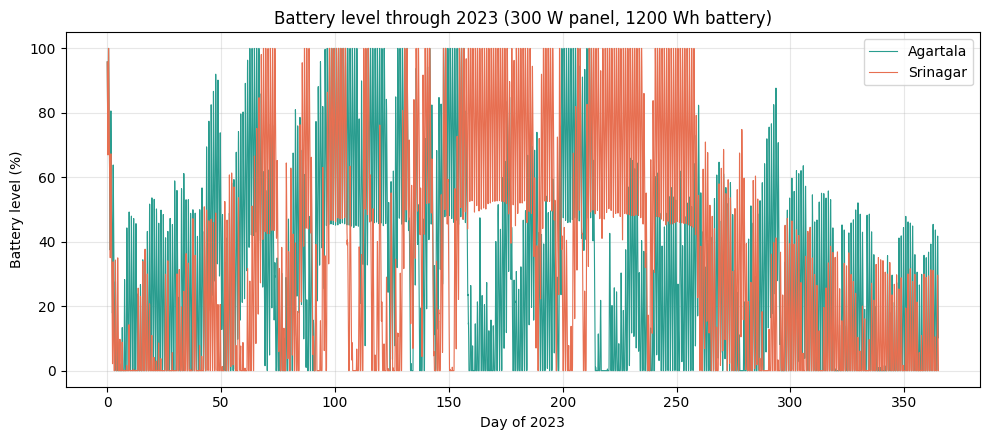

In [ ]:
import numpy as np

mon = sim[(sim["month"] > 0) & (sim["panel_w"] == DESIGN_W)].pivot(index="city", columns="month", values="uptime")
order = sizing.sort_values("avail_design")["city"].tolist()
show = order[:12] + [c for c in order[-12:] if c not in order[:12]]      # 12 riskiest + 12 safest cities
H = mon.loc[show] * 100
plt.figure(figsize=(9, 0.32 * len(show) + 1.8))
plt.imshow(H.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
plt.colorbar(label="Hours powered (%)")
plt.yticks(range(len(show)), show, fontsize=8)
plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title(f"Which months are risky? ({DESIGN_W} W panel, {BATTERY_WH} Wh battery)")
plt.tight_layout(); plt.savefig("C4_monthly_uptime.png", dpi=200); plt.show()

def soc_series(g, P):
    k = P * PR / 1000.0; soc = float(BATTERY_WH); out = []
    for x in g:
        soc += x * k - LOAD_W
        if soc > BATTERY_WH: soc = BATTERY_WH
        if soc < 0: soc = 0.0
        out.append(soc / BATTERY_WH * 100)
    return out

ly = df.agg(F.max("year")).collect()[0][0]
plt.figure(figsize=(10, 4.5))
for c, col in [(small["city"], "#2a9d8f"), (big["city"], "#e76f51")]:
    d = (df.filter((F.col("city") == c) & (F.col("year") == ly))
           .select("month", "day", "hour", "ghi").orderBy("month", "day", "hour").toPandas())
    ser = soc_series(d["ghi"].astype(float).tolist(), DESIGN_W)
    plt.plot(np.arange(len(ser)) / 24, ser, linewidth=0.8, color=col, label=c)
plt.xlabel(f"Day of {ly}"); plt.ylabel("Battery level (%)")
plt.title(f"Battery level through {ly} ({DESIGN_W} W panel, {BATTERY_WH} Wh battery)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("C5_battery_level.png", dpi=200); plt.show()

In [ ]:
from google.colab import files
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.image as mpimg, textwrap, glob

lines = [
    "Part C: Energy planning for solar-powered ecosystem monitoring stations (illustrative design study)",
    f"Assumptions: load {LOAD_W} W 24 h a day, battery {BATTERY_WH} Wh, system efficiency {PR:.0%}, target uptime {TARGET:.0%}, flat-surface NASA sunlight",
    f"Cities simulated: {len(sizing)} | Hourly records used: {n_B:,}",
    f"Cities reaching target with up to {max(PANEL_SIZES)} W: {n_ok} of {len(sizing)}",
    f"Smallest panel: {small['city']} ({label(small['plot_w'])}) | Largest: {big['city']} ({label(big['plot_w'])})",
    f"Example design ({DESIGN_W} W panel): average share of hours powered across cities = {sizing['avail_design'].mean():.1%}",
]
tbl = sizing.sort_values("min_panel_w")[["city", "min_panel_w", "avail_design"]].round(3)

with PdfPages("PartC_results.pdf") as pdf:
    fig = plt.figure(figsize=(11.69, 8.27))
    fig.text(0.05, 0.92, "Part C: Energy planning for ecosystem monitoring", fontsize=20, fontweight="bold")
    y = 0.84
    for ln in lines:
        for part in textwrap.wrap(ln, 110):
            fig.text(0.05, y, part, fontsize=12); y -= 0.04
        y -= 0.01
    pdf.savefig(fig); plt.close(fig)
    fig, ax = plt.subplots(figsize=(11.69, 8.27)); ax.axis("off")
    t = ax.table(cellText=tbl.values, colLabels=list(tbl.columns), loc="upper center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(6)
    pdf.savefig(fig); plt.close(fig)
    for f in sorted(glob.glob("C*.png")):
        fig, ax = plt.subplots(figsize=(11.69, 8.27)); ax.imshow(mpimg.imread(f)); ax.axis("off")
        pdf.savefig(fig, dpi=200); plt.close(fig)
files.download("PartC_results.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, time, warnings, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figs", exist_ok=True)
TEAL, AMBER, RED, GREY = "#1f8a70", "#f5a300", "#d9573b", "#8da0cb"
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":300, "axes.grid":True, "grid.alpha":0.3,
                     "font.size":12, "axes.titleweight":"bold"})
def save(name): plt.tight_layout(); plt.savefig(f"figs/{name}.png", bbox_inches="tight"); plt.show()

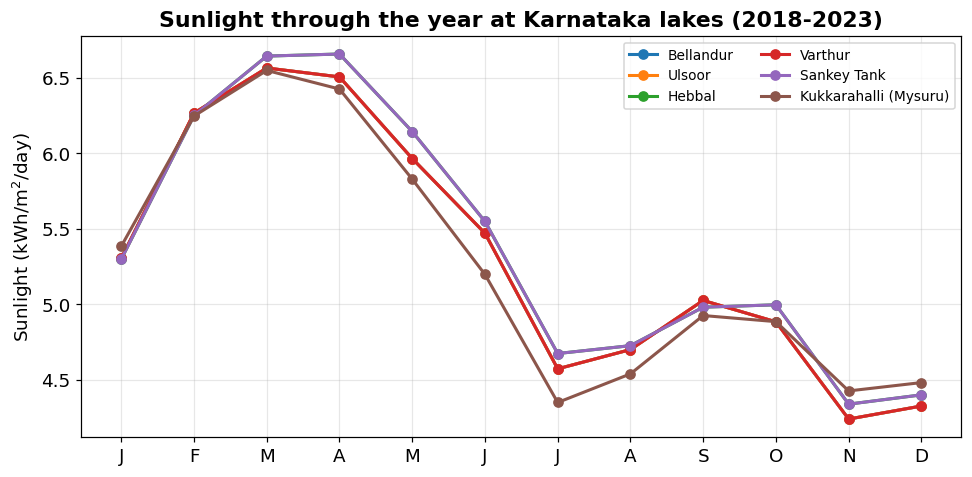

Dullest month per lake: {'Bellandur': 11, 'Ulsoor': 11, 'Hebbal': 11, 'Varthur': 11, 'Sankey Tank': 11, 'Kukkarahalli (Mysuru)': 7}


In [ ]:
import pickle
# APPROXIMATE centre points: verify each on Google Maps
LAKES = {"Bellandur":(12.935,77.670), "Ulsoor":(12.983,77.619), "Hebbal":(13.045,77.590),
         "Varthur":(12.938,77.741), "Sankey Tank":(13.008,77.573), "Kukkarahalli (Mysuru)":(12.310,76.635)}
YEARS = list(range(2018, 2024))

def nasa_hourly(lat, lon, years=YEARS):
    out = []
    for y in years:
        for attempt in range(3):
            try:
                r = requests.get("https://power.larc.nasa.gov/api/temporal/hourly/point", timeout=180, params={
                    "parameters":"ALLSKY_SFC_SW_DWN","community":"RE","longitude":lon,"latitude":lat,
                    "start":f"{y}0101","end":f"{y}1231","format":"JSON","time-standard":"LST"})
                r.raise_for_status(); break
            except Exception as e:
                print("retry", y, e); time.sleep(5)
        v = pd.Series(r.json()["properties"]["parameter"]["ALLSKY_SFC_SW_DWN"]).sort_index().astype(float)
        v = v.where(v > -900).interpolate(limit=3).fillna(0)      # NASA fill value is -999
        out.append(v.values)
    return out

if os.path.exists("yearly.pkl"): yearly = pickle.load(open("yearly.pkl","rb"))
else:
    yearly = {k: nasa_hourly(*v) for k,v in LAKES.items()}; pickle.dump(yearly, open("yearly.pkl","wb"))

# Figure B1: monthly sunlight at the lakes (monsoon dip)
def monthly(arrs):
    s = []
    for y, a in zip(YEARS, arrs):
        ser = pd.Series(a, index=pd.date_range(f"{y}-01-01", periods=len(a), freq="h"))
        s.append(ser.resample("D").sum().div(1000).groupby(lambda t: t.month).mean())   # kWh/m2/day
    return pd.concat(s, axis=1).mean(axis=1)
mon = pd.DataFrame({k: monthly(v) for k,v in yearly.items()})
ax = mon.plot(figsize=(9,4.5), marker="o", lw=2)
ax.set_xticks(range(1,13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_ylabel("Sunlight (kWh/m$^2$/day)"); ax.set_title("Sunlight through the year at Karnataka lakes (2018-2023)")
ax.legend(fontsize=9, ncol=2); save("B1_lake_monthly_sunlight")
print("Dullest month per lake:", mon.idxmin().to_dict())